# Pipe rheometry and calibration design

An engineer who needs the pressure gradient for pumping a yield-stress fluid through a pipe has two questions: which Herschel–Bulkley (HB) triplet $(\sigma_y, K, n)$ to use, and how much the answer depends on where that triplet came from. This notebook works through both with the material of Supplementary Note S5. First, three published triplets for one Carbopol solution (Magnon and Cayeux, 2021) disagree by up to 24% in yield stress, yet give almost the same pressure loss at high flow rates; we find out why. Second, a synthetic repeated-experiment study shows how the range of shear rates used for calibration controls the spread of predicted pressure gradients, and why that spread must be judged at the operating point.

### Where this is in the review
* **Supplementary Note S5**, "Pipe rheometry: parameter disagreement, hydraulic agreement and calibration design": **Table SIII** (the three triplets), Sec. S5 B (the synthetic study), **Fig. S3** (script `scripts/figS3_pipe_uncertainty.py`, which uses the exact pipe model in `scripts/hb_prediction.py`).
* Article **Sec. VI E** (the dominance of systematic error) and **Sec. VI F** (propagating parameter uncertainty to an application output, **Eq. (17)**); **Sec. VI D** for the reparameterization $\sigma=\sigma_y+A(\dot\gamma/\dot\gamma_*)^n$ and the ill-conditioning of HB fits; the exact pipe solution, **Sec. VII A, Eqs. (18)–(19)**; **Sec. IX E** and row F of **Table XII** (rotational to pipe pressure); Sec. V B for the critical shear rate $\dot\gamma_c$.
* Data: `data/pipe_supplement_results.json`, the stored synthetic ensembles `data/{broad_window,high_rate_window,cutoff_1s_window}_{fits,pressure}.csv`, and the plotted series in `data/figure_data/figS3_pipe.csv`.

### Learning objectives
1. Compute the pressure gradient for a given flow rate from the exact HB pipe solution, and check it against its classical limits.
2. Explain why triplets that disagree in $\sigma_y$ can agree in pressure loss, using the plug fraction $\phi$ and sensitivity coefficients.
3. Describe the design of a repeated-experiment (Monte Carlo) study of calibration, run a small version, and read the stored full version.
4. Show that parameter precision and prediction precision differ, and that a calibration window must be chosen for the operating point.

In [1]:
# Standard set-up used by every notebook in this folder.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook runs from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
DATA = ROOT / "data"
FIGDATA = DATA / "figure_data"
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not leave compiled files in scripts/

# Plot style and palette of the article. hbstyle also defines save(), which rewrites the
# published figures and data: it is deliberately NOT imported or called here.
from hbstyle import C
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110})


def figure_series(df, panel, series):
    """x and y of one plotted series in a data/figure_data/<figure>.csv table."""
    s = df[(df["panel"] == panel) & (df["series"] == series)].sort_values("index")
    if s.empty:
        raise KeyError(f"no series {series!r} in panel {panel!r}")
    return s["x"].to_numpy(float), s["y"].to_numpy(float)

import json
from scipy.optimize import least_squares
from hb_prediction import pipe_flux, pressure_gradient     # exact no-slip laminar pipe model (SI units)

## 1. The forward model: pressure gradient from flow rate

In fully developed laminar pipe flow the wall shear stress is fixed by momentum balance, $\sigma_w=GR/2$, where $G$ is the pressure gradient and $R$ the radius (Sec. VII A). The plug fraction is $\phi=\sigma_y/\sigma_w=r_p/R$, and the flow rate is **Eq. (19)**:
$$Q=\pi R^3 n\left(\frac{\sigma_w}{K}\right)^{1/n}(1-\phi)^{\frac{n+1}{n}}\left[\frac{(1-\phi)^2}{3n+1}+\frac{2\phi(1-\phi)}{2n+1}+\frac{\phi^2}{n+1}\right],\qquad \sigma_w>\sigma_y,$$
and $Q=0$ for $\sigma_w\le\sigma_y$. Equation (19) gives $Q$ for a known $\sigma_w$; a design calculation needs the inverse, $G(Q)$, which is found by root-finding because Eq. (19) is implicit in $\sigma_w$. The functions `pipe_flux` and `pressure_gradient` of `scripts/hb_prediction.py` do exactly this (assumptions: laminar, no slip, fully developed). We also use the **apparent wall shear rate** $4Q/(\pi R^3)=8U/D$, the wall rate a Newtonian fluid would have at the same flow.

First we check `pipe_flux` against an independent transcription of Eq. (19), against direct integration of the velocity profile, Eq. (18), and against the Newtonian, power-law and Buckingham–Reiner limits; then we check that `pressure_gradient` inverts it.

In [2]:
def Q_eq19(sw, R, sy, K, n):
    """Flow rate from Eq. (19) (sw > sy)."""
    phi = sy / sw
    return np.pi * R**3 * n * (sw / K) ** (1 / n) * (1 - phi) ** ((n + 1) / n) * (
        (1 - phi) ** 2 / (3 * n + 1) + 2 * phi * (1 - phi) / (2 * n + 1) + phi**2 / (n + 1))

def Q_from_profile(sw, R, sy, K, n, npts=20001):
    """Flow rate by integrating the velocity profile of Eq. (18): Q = 2 pi int u r dr."""
    r = np.linspace(0, R, npts)
    excess = np.clip(sw * r / R - sy, 0, None)
    u = n / (n + 1) * R / sw * (1 / K) ** (1 / n) * ((sw - sy) ** ((n + 1) / n) - excess ** ((n + 1) / n))
    return np.trapezoid(2 * np.pi * r * u, r)

R_test, sw_test = 0.01, 25.0
for (sy, K, n) in [(10.0, 5.0, 0.5), (1.198, 0.2717, 0.6389), (0.0, 0.3, 1.0), (0.0, 2.0, 0.4), (8.0, 0.05, 1.0)]:
    q_lib = pipe_flux(sw_test, R_test, sy, K, n)
    assert np.isclose(q_lib, Q_eq19(sw_test, R_test, sy, K, n), rtol=1e-12)
    assert np.isclose(q_lib, Q_from_profile(sw_test, R_test, sy, K, n), rtol=1e-6)
# Limits: Hagen-Poiseuille, power law, Buckingham-Reiner
mu = 0.3
assert np.isclose(pipe_flux(sw_test, R_test, 0.0, mu, 1.0), np.pi * R_test**3 * sw_test / (4 * mu))
assert np.isclose(pipe_flux(sw_test, R_test, 0.0, 2.0, 0.4), np.pi * R_test**3 * 0.4 * (sw_test / 2.0) ** 2.5 / 2.2)
phi = 8.0 / sw_test
assert np.isclose(pipe_flux(sw_test, R_test, 8.0, mu, 1.0), np.pi * R_test**3 * sw_test / (4 * mu) * (1 - 4 * phi / 3 + phi**4 / 3))
assert pipe_flux(5.0, R_test, 8.0, mu, 1.0) == 0.0          # below the yield stress: no flow
# Inverse: G(Q) returns the wall stress that reproduces Q
q = pipe_flux(sw_test, R_test, 10.0, 5.0, 0.5)
G = pressure_gradient(q, R_test, 10.0, 5.0, 0.5)
assert np.isclose(G * R_test / 2, sw_test, rtol=1e-10)
print("pipe_flux agrees with Eq. (19) and with the integrated profile (Eq. 18), reproduces the Newtonian, power-law "
      "and Buckingham-Reiner limits, and pressure_gradient inverts it.")

pipe_flux agrees with Eq. (19) and with the integrated profile (Eq. 18), reproduces the Newtonian, power-law and Buckingham-Reiner limits, and pressure_gradient inverts it.


## 2. Three published triplets for one Carbopol solution

Magnon and Cayeux (2021) identified HB parameters for an aqueous Carbopol 980 solution in two ways: concentric-cylinder rheometry with a correction for the non-Newtonian shear-rate conversion, and pressure–flow measurements in a glass tube of internal diameter 15.5 mm with three differential-pressure sensors along the developed section ($27.9\pm0.6$ °C). The pipe analysis assumes laminar flow and no wall slip. Their three triplets (Table SIII):

In [3]:
pipe_res = json.loads((DATA / "pipe_supplement_results.json").read_text())
pub = pipe_res["published_triplets"]
triplets = pd.DataFrame(pub["sets"]).set_index("method")
triplets["d sigma_y / sigma_y,rot (%)"] = pub["yield_differences_percent"]
triplets["d K / K_rot (%)"] = 100 * (triplets["K_Pa_s_n"] / triplets.loc["Rotational", "K_Pa_s_n"] - 1)
triplets["d n / n_rot (%)"] = 100 * (triplets["n"] / triplets.loc["Rotational", "n"] - 1)
print("source doi:", pub["source_doi"])
print(triplets.round(4).to_string())
R_tube = 0.0155 / 2                                   # m

source doi: 10.3390/fluids6040157
                        yield_stress_Pa  K_Pa_s_n       n  d sigma_y / sigma_y,rot (%)  d K / K_rot (%)  d n / n_rot (%)
method                                                                                                                  
Rotational                        1.198    0.2717  0.6389                       0.0000           0.0000           0.0000
Pipe, nonlinear fit               1.030    0.2560  0.6490                     -14.0234          -5.7784           1.5808
Pipe, corrected method            0.909    0.2720  0.6410                     -24.1235           0.1104           0.3287


The pipe routes give yield stresses 14% and 24% below the rotational one, while $K$ is within 6% and $n$ within 2%. Insert each triplet into the exact pipe model for the 15.5-mm tube and compare the pressure gradients over 0.01–10 L/min.

In [4]:
flow_lmin = np.logspace(-2, 1, 120)                  # same grid as the script
q_tube = flow_lmin * 1e-3 / 60                        # m^3/s
grads = {m: np.array([pressure_gradient(q, R_tube, row.yield_stress_Pa, row.K_Pa_s_n, row.n) for q in q_tube])
         for m, row in triplets.iterrows()}
rel = {m: 100 * (g / grads["Rotational"] - 1) for m, g in grads.items()}
wall_rate_app = 4 * q_tube / (np.pi * R_tube**3)

for Q in (0.01, 0.1, 1.0, 10.0):
    i = int(np.argmin(abs(np.log(flow_lmin / Q))))
    phis = [triplets.loc[m, "yield_stress_Pa"] / (grads[m][i] * R_tube / 2) for m in triplets.index]
    print(f"Q = {flow_lmin[i]:6.3f} L/min (apparent wall rate {wall_rate_app[i]:7.2f} 1/s): "
          f"dG/G_rot = {rel['Pipe, nonlinear fit'][i]:6.2f}% and {rel['Pipe, corrected method'][i]:6.2f}%;  "
          f"plug fraction phi = {phis[0]:.2f}, {phis[1]:.2f}, {phis[2]:.2f}")

Q =  0.010 L/min (apparent wall rate    0.46 1/s): dG/G_rot = -12.77% and -20.44%;  plug fraction phi = 0.77, 0.76, 0.74
Q =  0.102 L/min (apparent wall rate    4.65 1/s): dG/G_rot = -10.37% and -15.02%;  plug fraction phi = 0.53, 0.51, 0.48
Q =  0.981 L/min (apparent wall rate   44.71 1/s): dG/G_rot =  -5.86% and  -6.83%;  plug fraction phi = 0.25, 0.22, 0.20
Q = 10.000 L/min (apparent wall rate  455.88 1/s): dG/G_rot =  -1.28% and  -1.02%;  plug fraction phi = 0.07, 0.06, 0.06


These are the numbers of Note S5: at 10 L/min (apparent wall rate about 460 s$^{-1}$) the pipe triplets predict pressure gradients within 1.3% of the rotational one; at 1 L/min (45 s$^{-1}$) the difference is 5.9–6.8%; at 0.01 L/min (0.46 s$^{-1}$) it reaches 13% and 20%. The printed plug fraction $\phi$ explains why. At high flow the wall stress is many times the yield stress ($\phi\approx0.06$–0.07), so most of the pipe is sheared well above yield and the pressure is set mainly by $K$ and $n$, on which the triplets agree. At low flow the plug fills most of the pipe ($\phi\approx0.75$) and the wall stress is close to $\sigma_y$, so the yield-stress difference passes almost one-to-one into the pressure.

### Sensitivity coefficients
A compact way to say the same thing (an illustration made for this notebook) is the logarithmic sensitivity of the predicted gradient to each parameter, $S_\theta=\partial\ln G/\partial\ln\theta$ at fixed $Q$, here for the rotational triplet. $S_{\sigma_y}$ is the fraction of a relative change in $\sigma_y$ that appears in $G$. For $n$, which sits in an exponent, we report $\partial\ln G/\partial n$.

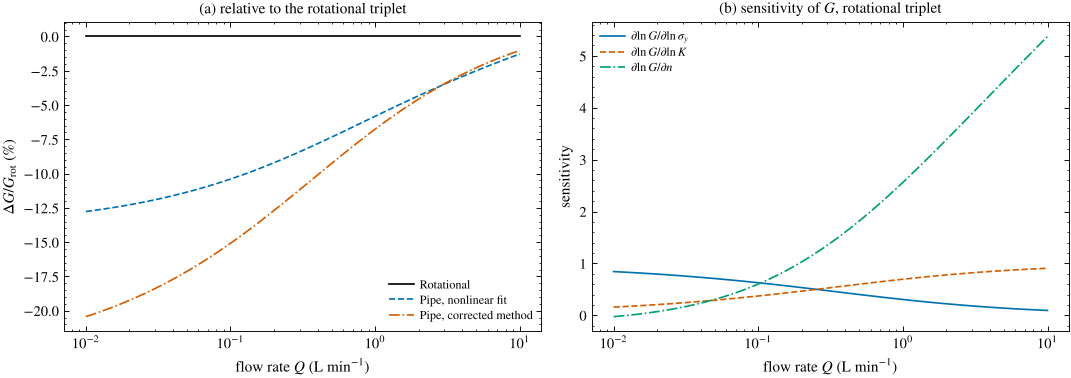

at 0.01 L/min: S_sigma_y = 0.84, S_K = 0.16;  at 10 L/min: S_sigma_y = 0.09, S_K = 0.91


In [5]:
rot = triplets.loc["Rotational"]
base = np.array([rot.yield_stress_Pa, rot.K_Pa_s_n, rot.n])

def lnG(theta, q):
    return np.log(pressure_gradient(q, R_tube, *theta))

S = []
for q in q_tube:
    row = []
    for j in range(3):
        h = 1e-5 * base[j]
        tp, tm = base.copy(), base.copy(); tp[j] += h; tm[j] -= h
        d = (lnG(tp, q) - lnG(tm, q)) / (2 * h)            # d lnG / d theta_j
        row.append(d * base[j] if j < 2 else d)           # log sensitivity for sigma_y and K; d lnG/dn for n
    S.append(row)
S = np.array(S)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.7))
for rr, (m, col, ls) in zip(rel.values(), [("Rotational", "k", "-"), ("Pipe, nonlinear fit", C["blue"], "--"), ("Pipe, corrected method", C["red"], "-.")]):
    ax[0].semilogx(flow_lmin, rr, ls, color=col, label=m)
ax[0].set(xlabel=r"flow rate $Q$ (L min$^{-1}$)", ylabel=r"$\Delta G/G_{\rm rot}$ (%)", title="(a) relative to the rotational triplet")
ax[0].legend(fontsize=8, loc="lower right")
ax[1].semilogx(flow_lmin, S[:, 0], color=C["blue"], label=r"$\partial\ln G/\partial\ln\sigma_y$")
ax[1].semilogx(flow_lmin, S[:, 1], color=C["red"], ls="--", label=r"$\partial\ln G/\partial\ln K$")
ax[1].semilogx(flow_lmin, S[:, 2], color=C["green"], ls="-.", label=r"$\partial\ln G/\partial n$")
ax[1].set(xlabel=r"flow rate $Q$ (L min$^{-1}$)", ylabel="sensitivity", title="(b) sensitivity of $G$, rotational triplet")
ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
print(f"at 0.01 L/min: S_sigma_y = {S[0, 0]:.2f}, S_K = {S[0, 1]:.2f};  at 10 L/min: S_sigma_y = {S[-1, 0]:.2f}, S_K = {S[-1, 1]:.2f}")

At the lowest flow a 1% change in $\sigma_y$ changes $G$ by about 0.8%; at the highest flow by under 0.1%, while $K$ and $n$ take over. Hydraulic agreement at moderate and high flow is therefore compatible with a 14–24% disagreement in $\sigma_y$; the yield stress becomes decisive only near the onset of flow.

Why are the pipe intercepts lower? The study does not say. Note S5 points out that wall slip of Carbopol on smooth glass, which the pipe analysis excludes by assumption, would lower the apparent pipe yield stress in exactly this way, and that it was not tested; measurements in tubes of several diameters, or velocimetry in the tube, would separate slip from a genuine difference between the instruments.

## 3. A synthetic study of the calibration window

Real data mix random scatter with slip, nonstationarity and other systematic errors (Sec. VI E). To isolate the effect of the **calibration window** alone, Note S5 B uses synthetic data from a known truth and asks how well the fitted triplets predict the pipe pressure. The design:

* **Truth:** $\sigma=\sigma_y+A(\dot\gamma/\dot\gamma_*)^n$ with $\sigma_y=10$ Pa, $A=5$ Pa, $\dot\gamma_*=1$ s$^{-1}$, $n=0.5$. With $\dot\gamma_*=1$ s$^{-1}$, $A$ equals $K$ numerically. (This reparameterization, used by Saasen and Ytrehus (2020) and close to that of Nelson and Ewoldt (2017), gives $A$ units of Pa for every $n$; Sec. VI D.)
* **Noise:** independent Gaussian stress noise, standard deviation 2 Pa.
* **Experiments:** 240 datasets per design, each with 24 logarithmically spaced rates, fitted by bounded nonlinear least squares ($0\le\sigma_y\le200$ Pa, $10^{-8}\le A\le200$ Pa, $0.1\le n\le1.4$; three starting values of $n$, best fit kept). The bound $\sigma_y\ge0$ matters, because unconstrained least squares can return a negative yield stress; Kelessidis et al. (2006) enforced positivity with a golden-section search on $\sigma_y$ (Sec. VI D).
* **Designs:** a broad window (0.1–1000 s$^{-1}$), a high-rate window (100–1000 s$^{-1}$), and a window truncated at 1 s$^{-1}$ (1–1000 s$^{-1}$), the usable range for a material whose critical shear rate is about 1 s$^{-1}$.
* **Prediction:** each fitted triplet predicts the pressure gradient in a 10-mm-radius pipe at the flow rates that give true wall rates of 0.01–1000 s$^{-1}$; the output is $G/G_{\rm true}$. Seed 20260920.

independent Gaussian stress, SD 2 Pa | radius 0.01 m | seed 20260920 | 240 datasets per design


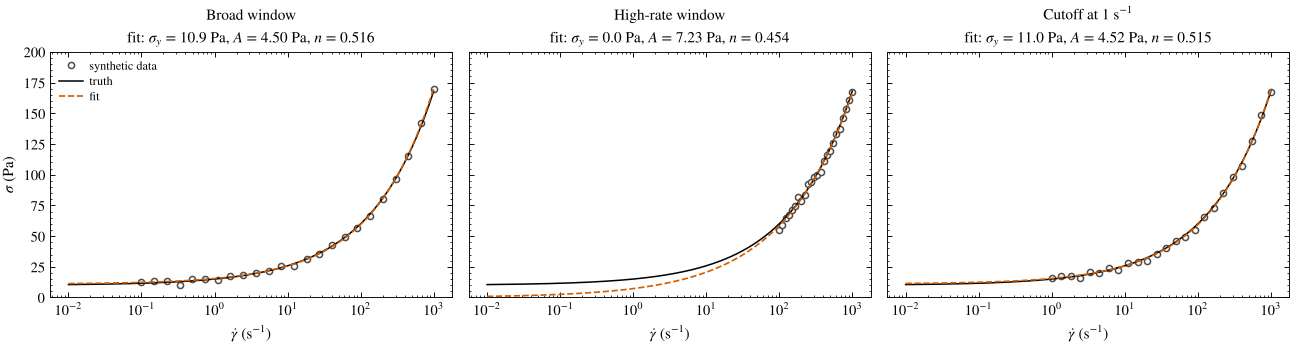

In [6]:
syn = pipe_res["synthetic"]
truth = np.array(syn["truth_sigma_y_A_n"])          # sigma_y (Pa), A (Pa) at 1 1/s, n
noise_sd, radius = 2.0, syn["radius_m"]
lower, upper = syn["fit_bounds"]
designs = {"Broad window": np.logspace(-1, 3, 24),
           "High-rate window": np.logspace(2, 3, 24),
           r"Cutoff at 1 s$^{-1}$": np.logspace(0, 3, 24)}
tags = {"Broad window": "broad_window", "High-rate window": "high_rate_window", r"Cutoff at 1 s$^{-1}$": "cutoff_1s_window"}
print(syn["noise"], "| radius", radius, "m | seed", syn["seed"], "|", syn["repeats"], "datasets per design")

def fit_hb(rates, y):
    """Bounded least squares from three starting values of n; returns (sigma_y, A, n) of the best fit."""
    resid = lambda t: (t[0] + t[1] * rates ** t[2] - y) / noise_sd
    cands = [least_squares(resid, [10.0, 5.0, n0], bounds=(lower, upper), xtol=1e-10, ftol=1e-10, gtol=1e-10, max_nfev=1500)
             for n0 in (0.25, 0.5, 0.85)]
    return min([r for r in cands if r.success], key=lambda r: r.cost).x

# One synthetic experiment per design, to see what the fits look like
rng_demo = np.random.default_rng(1)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
gg = np.logspace(-2, 3, 200)
for ax, (name, rates) in zip(axs, designs.items()):
    y = truth[0] + truth[1] * rates ** truth[2] + rng_demo.normal(0, noise_sd, rates.size)
    p = fit_hb(rates, y)
    ax.semilogx(rates, y, "o", ms=4, mfc="white", color="0.3", label="synthetic data")
    ax.semilogx(gg, truth[0] + truth[1] * gg ** truth[2], "k", lw=1, label="truth")
    ax.semilogx(gg, p[0] + p[1] * gg ** p[2], color=C["red"], ls="--", label="fit")
    ax.set(title=f"{name}\nfit: $\\sigma_y$ = {p[0]:.1f} Pa, $A$ = {p[1]:.2f} Pa, $n$ = {p[2]:.3f}", xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylim=(0, 200))
axs[0].set_ylabel(r"$\sigma$ (Pa)"); axs[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

Each fit passes through its own data. The question is what happens *outside* the window, at the low wall rates of a slow pipe flow.

### A small Monte Carlo run (50 datasets per design)
The full study (3 × 240 fits followed by 3 × 240 × 55 pressure calculations) takes a while, and its results are stored. To see how it works we repeat it with 50 datasets per design, using the same seed and procedure; the numbers will differ slightly from the stored ones because the sample is smaller.

In [7]:
rng = np.random.default_rng(syn["seed"])
small = {}
for name, rates in designs.items():
    fits = []
    for _ in range(50):
        y = truth[0] + truth[1] * rates ** truth[2] + rng.normal(0, noise_sd, rates.size)
        fits.append(fit_hb(rates, y))
    small[name] = np.array(fits)

# predict the pipe pressure at the lowest and highest true wall rates
wall_rates = np.logspace(-2, 3, 55)                                   # grid of the script
true_w = truth[0] + truth[1] * wall_rates ** truth[2]                  # true wall stress
flow = pipe_flux(true_w, radius, *truth)                               # flow rates that give these wall rates
true_grad = 2 * true_w / radius
for name, fits in small.items():
    lo_hi = []
    for i in (0, len(wall_rates) - 1):
        ratio = np.array([pressure_gradient(flow[i], radius, *f) for f in fits]) / true_grad[i]
        lo_hi.append(np.quantile(ratio, [0.025, 0.975]))
    label = name.replace("$^{-1}$", "^-1")
    print(f"{label:22s} sigma_y 95% range {np.quantile(fits[:, 0], 0.025):5.1f}-{np.quantile(fits[:, 0], 0.975):5.1f} Pa, "
          f"zero-yield fits {np.sum(fits[:, 0] < 1e-5):2d}/50;  G/G_true 95% range at 0.01 1/s: {lo_hi[0][0]:.2f}-{lo_hi[0][1]:.2f}, "
          f"at 1000 1/s: {lo_hi[1][0]:.3f}-{lo_hi[1][1]:.3f}")

Broad window           sigma_y 95% range   8.3- 11.4 Pa, zero-yield fits  0/50;  G/G_true 95% range at 0.01 1/s: 0.84-1.13, at 1000 1/s: 0.991-1.011
High-rate window       sigma_y 95% range   0.0- 20.1 Pa, zero-yield fits  8/50;  G/G_true 95% range at 0.01 1/s: 0.03-1.95, at 1000 1/s: 0.993-1.007
Cutoff at 1 s^-1       sigma_y 95% range   7.5- 11.6 Pa, zero-yield fits  0/50;  G/G_true 95% range at 0.01 1/s: 0.77-1.15, at 1000 1/s: 0.989-1.012


With only 50 datasets the 2.5% and 97.5% quantiles are themselves noisy, but the pattern is already clear: every window predicts the high-flow pressure to about ±1%, while at the lowest flow the high-rate window is far worse than the other two, and some of its fits fall on the zero-yield boundary.

### The stored full study (240 datasets per design)

          design sigma_y 2.5-97.5% (Pa) A 2.5-97.5% (Pa) n 2.5-97.5%  zero-yield fits
    Broad window               8.3-11.5        4.29-5.86 0.477-0.523                0
High-rate window               0.0-23.0        2.56-7.63 0.446-0.585               30
Cutoff at 1 s^-1               7.2-12.4        4.10-5.94 0.476-0.529                0


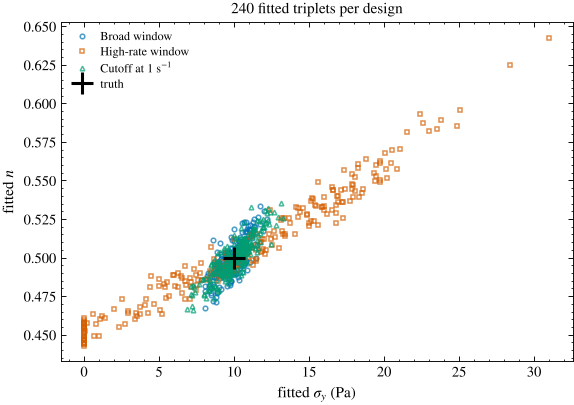

In [8]:
stored_fits = {name: np.loadtxt(DATA / f"{tag}_fits.csv", delimiter=",", skiprows=1) for name, tag in tags.items()}
stored_press = {name: pd.read_csv(DATA / f"{tag}_pressure.csv") for name, tag in tags.items()}
rows = []
for name, fits in stored_fits.items():
    q = np.quantile(fits, [0.025, 0.5, 0.975], axis=0)
    rows.append({"design": name.replace("$^{-1}$", "^-1"), "sigma_y 2.5-97.5% (Pa)": f"{q[0, 0]:.1f}-{q[2, 0]:.1f}",
                 "A 2.5-97.5% (Pa)": f"{q[0, 1]:.2f}-{q[2, 1]:.2f}", "n 2.5-97.5%": f"{q[0, 2]:.3f}-{q[2, 2]:.3f}",
                 "zero-yield fits": int(np.sum(fits[:, 0] < 1e-5))})
    summ = syn["results"][tags[name]]
    assert np.allclose(q, summ["parameter_q025_q50_q975"]) and rows[-1]["zero-yield fits"] == summ["zero_yield_boundary_fits"]
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
for (name, fits), col, mk in zip(stored_fits.items(), [C["blue"], C["red"], C["green"]], ["o", "s", "^"]):
    ax.plot(fits[:, 0], fits[:, 2], mk, ms=3, color=col, mfc="none", alpha=0.7, label=name)
ax.plot(truth[0], truth[2], "k+", ms=14, mew=2, label="truth")
ax.set(xlabel=r"fitted $\sigma_y$ (Pa)", ylabel="fitted $n$", title="240 fitted triplets per design")
ax.legend(fontsize=8); plt.show()

The broad window pins $\sigma_y$ to 8.3–11.5 Pa. The high-rate window spreads it over 0–23 Pa, and 30 of its 240 fits land on the zero-yield boundary: data between 100 and 1000 s$^{-1}$ hardly see the yield stress, and the fit trades $\sigma_y$ against $n$ along the valley of Sec. VI D. Truncating at 1 s$^{-1}$ widens the range only modestly (7.2–12.4 Pa, no boundary fits): three decades of data still constrain the triplet.

Now the prediction. We recompute $G/G_{\rm true}$ from the stored triplets at three wall rates and compare with the stored quantile bands.

In [9]:
for name, fits in stored_fits.items():
    band = stored_press[name]
    for i in (0, 27, 54):                                        # true wall rates 0.01, 3.16 and 1000 1/s
        ratio = np.array([pressure_gradient(flow[i], radius, *f) for f in fits]) / true_grad[i]
        q = np.quantile(ratio, [0.025, 0.5, 0.975])
        ref = band.iloc[i][["q025_G_over_true", "q50_G_over_true", "q975_G_over_true"]].to_numpy(float)
        assert np.allclose(q, ref, rtol=1e-10), (name, i)
        assert np.isclose(band.iloc[i]["true_wall_rate_s_inv"], wall_rates[i]) and np.isclose(band.iloc[i]["Q_L_min"], flow[i] * 6e4)
    lo, hi = band["q025_G_over_true"], band["q975_G_over_true"]
    label = name.replace("$^{-1}$", "^-1")
    print(f"{label:22s} 95% range of G/G_true: at 0.01 1/s {lo.iloc[0]:.2f}-{hi.iloc[0]:.2f};  at 1000 1/s {lo.iloc[-1]:.3f}-{hi.iloc[-1]:.3f}")
print("recomputed quantiles agree with the stored *_window_pressure.csv files (relative tolerance 1e-10)")

Broad window           95% range of G/G_true: at 0.01 1/s 0.84-1.14;  at 1000 1/s 0.987-1.013


High-rate window       95% range of G/G_true: at 0.01 1/s 0.03-2.22;  at 1000 1/s 0.992-1.009


Cutoff at 1 s^-1       95% range of G/G_true: at 0.01 1/s 0.74-1.22;  at 1000 1/s 0.988-1.012
recomputed quantiles agree with the stored *_window_pressure.csv files (relative tolerance 1e-10)


At the highest flow every design predicts the pressure within about ±1.3%: in that regime the pressure depends on the flow curve near 1000 s$^{-1}$, which every window measures. At the lowest flow the 95% range is 0.84–1.14 for the broad window but 0.03–2.22 for the high-rate window: a fit that looks excellent in its own window can be wrong by a factor of two, or by a factor of thirty when it lands on $\sigma_y=0$, at the operating point that matters for restart and arrest. Parameter precision and prediction precision must therefore be assessed at the operating point rather than globally.

## 4. Reproducing Fig. S3 and checking it against the figure data

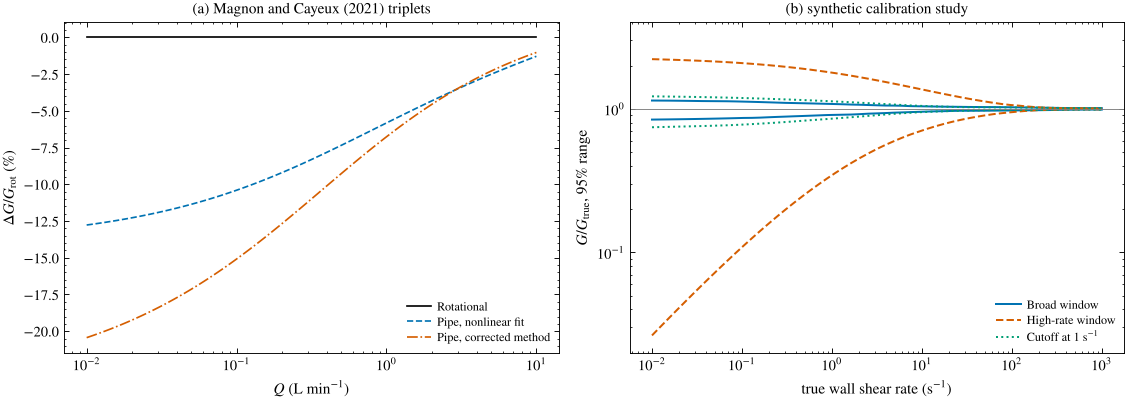

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))
for (m, rr), col, ls in zip(rel.items(), ["k", C["blue"], C["red"]], ["-", "--", "-."]):
    ax[0].semilogx(flow_lmin, rr, ls, color=col, label=m)
ax[0].set(xlabel=r"$Q$ (L min$^{-1}$)", ylabel=r"$\Delta G/G_{\rm rot}$ (%)", title="(a) Magnon and Cayeux (2021) triplets")
ax[0].legend(loc="lower right", fontsize=8)
for (name, band), col, ls in zip(stored_press.items(), [C["blue"], C["red"], C["green"]], ["-", "--", ":"]):
    ax[1].loglog(band["true_wall_rate_s_inv"], band["q025_G_over_true"], ls, color=col, lw=1.3, label=name)
    ax[1].loglog(band["true_wall_rate_s_inv"], band["q975_G_over_true"], ls, color=col, lw=1.3)
ax[1].axhline(1, color="0.5", lw=0.6)
ax[1].set(xlabel=r"true wall shear rate (s$^{-1}$)", ylabel=r"$G/G_{\rm true}$, 95% range", ylim=(0.02, 4),
          title="(b) synthetic calibration study")
ax[1].legend(loc="lower right", fontsize=8)
fig.tight_layout(); plt.show()

In [11]:
fdS3 = pd.read_csv(FIGDATA / "figS3_pipe.csv", comment="#")
RTOL = 1e-8
for m, rr in rel.items():
    x, y = figure_series(fdS3, "(a)", m)
    assert np.allclose(x, flow_lmin, rtol=RTOL) and np.allclose(y, rr, rtol=RTOL, atol=1e-9), m
for name, band in stored_press.items():
    x, y = figure_series(fdS3, "(b)", f"{name}: lower bound of 95% range")
    assert np.allclose(x, wall_rates, rtol=RTOL) and np.allclose(y, band["q025_G_over_true"], rtol=RTOL), name
    x, y = figure_series(fdS3, "(b)", f"{name}: upper bound of 95% range")
    assert np.allclose(y, band["q975_G_over_true"], rtol=RTOL), name
# headline numbers of the stored JSON
for Q, key in ((0.01, "0.01"), (10.0, "10")):
    i = int(np.argmin(abs(np.log(flow_lmin / Q))))
    stored_pt = pub["pressure_difference_percent_at_Q_L_min"][key]
    assert np.isclose(stored_pt["nonlinear_fit"], rel["Pipe, nonlinear fit"][i], rtol=1e-8)
    assert np.isclose(stored_pt["corrected_method"], rel["Pipe, corrected method"][i], rtol=1e-8)
print("Fig. S3 check passed: the 3 pressure-difference curves of panel (a), recomputed from the published triplets, and the "
      "6 band edges of panel (b) agree with figS3_pipe.csv (relative tolerance 1e-8) and with pipe_supplement_results.json.")

Fig. S3 check passed: the 3 pressure-difference curves of panel (a), recomputed from the published triplets, and the 6 band edges of panel (b) agree with figS3_pipe.csv (relative tolerance 1e-8) and with pipe_supplement_results.json.


## 5. First-order propagation versus the ensemble

Section VI F of the article gives the first-order (delta-method) estimate of the output variance, **Eq. (17)**:
$${\rm Var}(H)\simeq\nabla H^{T}\,\Sigma_\theta\,\nabla H,$$
where $\Sigma_\theta$ is the covariance matrix of the parameters, **including the covariance terms**. As an illustration made for this notebook, take $H=G/G_{\rm true}$, use the covariance of the 240 stored triplets for $\Sigma_\theta$, compute $\nabla H$ at the true parameters by finite differences, and compare $\pm1.96$ standard deviations with the ensemble's 95% range. We also show what happens if the covariance terms are dropped.

In [12]:
def grad_H(i, theta=truth):
    """Gradient of G/G_true with respect to (sigma_y, A, n) at flow index i, by central differences."""
    g = np.zeros(3)
    for j in range(3):
        h = 1e-6 * max(abs(theta[j]), 1e-3)
        tp, tm = theta.copy(), theta.copy(); tp[j] += h; tm[j] -= h
        g[j] = (pressure_gradient(flow[i], radius, *tp) - pressure_gradient(flow[i], radius, *tm)) / (2 * h) / true_grad[i]
    return g

rows = []
for name, fits in stored_fits.items():
    Sigma = np.cov(fits.T)
    band = stored_press[name]
    for i in (0, 27, 54):
        gH = grad_H(i)
        sd_full = np.sqrt(gH @ Sigma @ gH)
        sd_diag = np.sqrt(gH**2 @ np.diag(Sigma))
        rows.append({"design": name.replace("$^{-1}$", "^-1"), "true wall rate (1/s)": round(wall_rates[i], 2),
                     "ensemble 95% range": f"{band['q025_G_over_true'].iloc[i]:.3f}-{band['q975_G_over_true'].iloc[i]:.3f}",
                     "Eq. (17), with covariance": f"{1 - 1.96 * sd_full:.3f}-{1 + 1.96 * sd_full:.3f}",
                     "variances only": f"{1 - 1.96 * sd_diag:.3f}-{1 + 1.96 * sd_diag:.3f}"})
print(pd.DataFrame(rows).to_string(index=False))

          design  true wall rate (1/s) ensemble 95% range Eq. (17), with covariance variances only
    Broad window                  0.01        0.842-1.142               0.844-1.156    0.837-1.163
    Broad window                  3.16        0.930-1.059               0.933-1.067    0.881-1.119
    Broad window               1000.00        0.987-1.013               0.984-1.016    0.801-1.199
High-rate window                  0.01        0.026-2.219              -0.268-2.268   -0.299-2.299
High-rate window                  3.16        0.525-1.580               0.385-1.615    0.154-1.846
High-rate window               1000.00        0.992-1.009               0.904-1.096    0.300-1.700
Cutoff at 1 s^-1                  0.01        0.744-1.222               0.775-1.225    0.766-1.234
Cutoff at 1 s^-1                  3.16        0.903-1.087               0.909-1.091    0.836-1.164
Cutoff at 1 s^-1               1000.00        0.988-1.012               0.984-1.016    0.767-1.233


For the broad and truncated windows the linear estimate with covariance reproduces the ensemble range well at every flow. Dropping the covariance terms overstates the spread at high flow by a factor of 15–20, because the errors in $\sigma_y$, $A$ and $n$ compensate one another inside the calibrated range; this is the article's warning that varying parameters independently generates combinations that the data never supported (Sec. VI F). For the high-rate window the linear estimate fails at every flow: it gives a negative lower bound at the lowest flow and a range about ten times too wide at the highest. The fitted triplets lie along a curved valley and pile up at the $\sigma_y=0$ bound (see the scatter plot above), where a local covariance is unreliable (Sec. VI D); near thresholds the forward problem is strongly nonlinear, and sampling the joint parameter region is preferable.

## 6. What this does not include

The random-noise study bounds the uncertainty **from below**. For a material with a critical shear rate of about 1 s$^{-1}$ the truncated window looks statistically harmless (0.74–1.22 at the lowest flow), but below $\dot\gamma_c$ the material has no steady HB branch: pipe predictions at wall rates below 1 s$^{-1}$ extrapolate a flow curve that does not exist, and the error is then set by localized flow physics, not by the parameter spread. At low flow, model discrepancy and systematic errors (slip, banding, nonstationarity) dominate (Sec. VI E; Note S5 B).

## Try it yourself

**Exercise 1 — a middle window.** Repeat the small Monte Carlo for a window of 10–1000 s$^{-1}$ (24 rates, 50 datasets). Where does its low-flow 95% range fall between the broad and the high-rate windows?
*Hint:* add `"Middle window": np.logspace(1, 3, 24)` to a copy of `designs`.

**Exercise 2 — when do the published triplets diverge?** For the Magnon–Cayeux tube, find the flow rate below which the corrected-method triplet predicts a pressure gradient more than 10% below the rotational one. What is the plug fraction there?
*Hint:* use `rel["Pipe, corrected method"]` and interpolate in $\log Q$.

**Exercise 3 — more points or a wider window?** For the high-rate window, double the number of rates to 48 (same range) and repeat the small study. Does it narrow the low-flow range as much as widening the window does?

<details><summary>Solutions (click to expand)</summary>

1. With 10–1000 s$^{-1}$ (seed 2026 in the code below) the low-flow range is about 0.58–1.45: much better than 100–1000 s$^{-1}$ and clearly worse than 0.1–1000 s$^{-1}$. The exact numbers vary with the seed, because 50 replicates give noisy 2.5% and 97.5% quantiles.
2. Below about 0.41 L/min (apparent wall rate about 19 s$^{-1}$), where the rotational plug fraction is about 0.35.
3. No. With 48 points in 100–1000 s$^{-1}$ the low-flow range is still about 0.03–1.65, far wider than the 0.84–1.14 of the broad window, and fits still reach the zero-yield bound. The problem is the lack of information about the low-rate curve, not the amount of data.
</details>

In [13]:
# Optional solution code (uncomment to run)
# # 1 and 3
# rng_ex = np.random.default_rng(2026)
# for name, rates in {"Middle window": np.logspace(1, 3, 24), "High-rate, 48 points": np.logspace(2, 3, 48)}.items():
#     fits = np.array([fit_hb(rates, truth[0] + truth[1] * rates ** truth[2] + rng_ex.normal(0, noise_sd, rates.size)) for _ in range(50)])
#     ratio = np.array([pressure_gradient(flow[0], radius, *f) for f in fits]) / true_grad[0]
#     print(name, np.quantile(ratio, [0.025, 0.975]))
# # 2
# lq = np.log(flow_lmin); target = -10.0
# r_c = rel["Pipe, corrected method"]
# Q10 = np.exp(np.interp(target, r_c, lq))          # r_c increases with Q
# G_rot = np.exp(np.interp(np.log(Q10), lq, np.log(grads["Rotational"])))
# print(Q10, "L/min; apparent wall rate", 4 * Q10 * 1e-3 / 60 / (np.pi * R_tube**3), "1/s; phi_rot", rot.yield_stress_Pa / (G_rot * R_tube / 2))

## Key points
* The exact laminar no-slip pipe model, Eq. (19), gives $Q(\sigma_w)$; design needs its inverse $G(Q)$, found by root-finding. Check any implementation against Eq. (18) and the Newtonian, power-law and Buckingham–Reiner limits.
* Three triplets for one Carbopol solution differ by 14–24% in $\sigma_y$ yet predict pressure gradients within 1.3% at 10 L/min; the differences grow to 13–20% at 0.01 L/min. The plug fraction $\phi$ and the sensitivity $\partial\ln G/\partial\ln\sigma_y$ explain why: the yield stress matters only near the onset of flow. Wall slip on glass, not tested, could explain the lower pipe intercepts.
* In a synthetic study with 2 Pa noise, all calibration windows predict the high-flow pressure within about ±1.3%, but at the lowest flow the 95% range of $G/G_{\rm true}$ is 0.84–1.14 for a 0.1–1000 s$^{-1}$ window and 0.03–2.22 for a 100–1000 s$^{-1}$ window.
* Parameter precision and prediction precision differ; judge a calibration at the operating point. First-order propagation, Eq. (17), works only with the covariance terms and fails near bounds and thresholds.
* Random-noise studies are a lower bound: below a critical shear rate there is no HB branch to extrapolate, and at low flow systematic errors dominate.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Buckingham, E. (1921). On plastic flow through capillary tubes. *Proceedings of the American Society for Testing Materials* **21**, 1154–1156.
* Herschel, W. H., and Bulkley, R. (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**(4), 291–300. https://doi.org/10.1007/bf01432034
* Kelessidis, V. C., Maglione, R., Tsamantaki, C., and Aspirtakis, Y. (2006). Optimal determination of rheological parameters for Herschel–Bulkley drilling fluids and impact on pressure drop, velocity profiles and penetration rates during drilling. *Journal of Petroleum Science and Engineering* **53**(3–4), 203–224. https://doi.org/10.1016/j.petrol.2006.06.004
* Magnon, E., and Cayeux, E. (2021). Precise method to estimate the Herschel–Bulkley parameters from pipe rheometer measurements. *Fluids* **6**(4), 157. https://doi.org/10.3390/fluids6040157
* Nelson, A. Z., and Ewoldt, R. H. (2017). Design of yield-stress fluids: a rheology-to-structure inverse problem. *Soft Matter* **13**(41), 7578–7594. https://doi.org/10.1039/C7SM00758B
* Saasen, A., and Ytrehus, J. D. (2020). Viscosity models for drilling fluids—Herschel–Bulkley parameters and their use. *Energies* **13**(20), 5271. https://doi.org/10.3390/en13205271

### Further reading

* Chhabra, R. P., and Richardson, J. F. (2008). *Non-Newtonian Flow and Applied Rheology: Engineering Applications*, 2nd ed. Butterworth-Heinemann, Oxford.